In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [13]:
# Condiciones iniciales
N = 1000
S0 = 990
I0 = 10
R0 = 0
beta = 0.30
gamma = 0.10

In [14]:
reproduccion = beta / gamma

In [15]:
def sir(t, y):
    S, I, R = y

    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I

    return [dSdt, dIdt, dRdt]

In [16]:
dias = np.linspace(0, 160, 1601)

solucion = solve_ivp(
    sir,
    [0, 160],
    [S0, I0, R0],
    t_eval=dias,
    rtol=1e-9,
    atol=1e-11
)

S, I, R = solucion.y

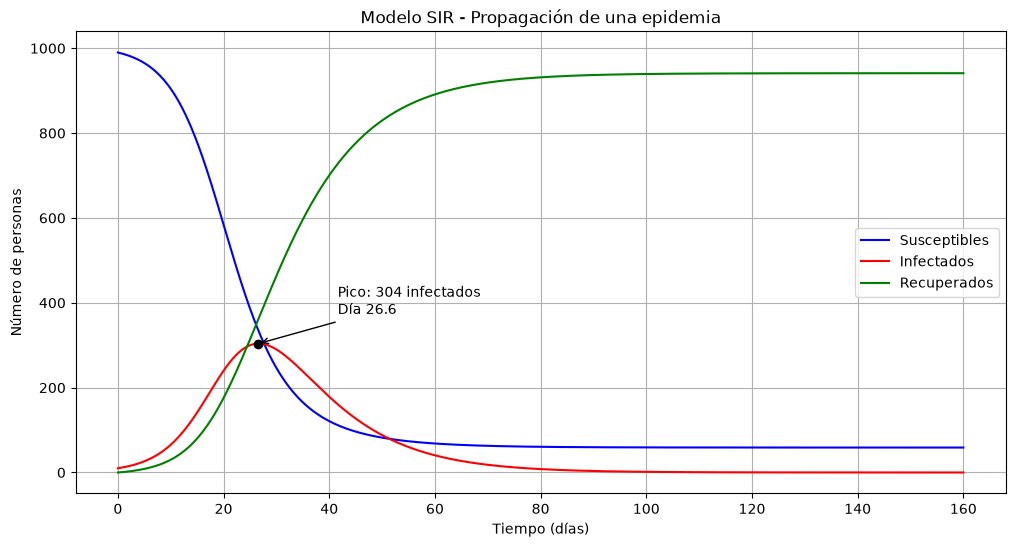

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(dias, S, label="Susceptibles", color="blue")
plt.plot(dias, I, label="Infectados", color="red")
plt.plot(dias, R, label="Recuperados", color="green")

indice_pico = np.argmax(I)
dia_pico = dias[indice_pico]
infectados_pico = I[indice_pico]

plt.scatter(dia_pico, infectados_pico, color="black", zorder=5)

plt.annotate(
    f"Pico: {infectados_pico:.0f} infectados\nDía {dia_pico:.1f}",
    (dia_pico, infectados_pico),
    xytext=(dia_pico + 15, infectados_pico + 70),
    arrowprops=dict(arrowstyle="->")
)

plt.title("Modelo SIR - Propagación de una epidemia")
plt.xlabel("Tiempo (días)")
plt.ylabel("Número de personas")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
dia_pico = dias[np.argmax(I)]
max_infectados = np.max(I)
recuperados_final = R[-1]
nunca_infectados = S[-1]

print("ANÁLISIS DEL MODELO SIR\n")

print(f"1. ¿Cuándo ocurre el pico epidémico?")
print(f"   Día {dia_pico:.1f}\n")

print(f"2. ¿Cuántos se infectan en el punto máximo?")
print(f"   {max_infectados:.0f} personas\n")

print(f"3. ¿Cuántos se recuperan al final?")
print(f"   {recuperados_final:.0f} personas\n")

print(f"4. ¿Cuántos nunca se infectan?")
print(f"   {nunca_infectados:.0f} personas\n")

print("5. ¿Por qué la curva de infectados crece y luego disminuye?")
print(
    "Inicialmente aumenta porque los contagios superan "
    "las recuperaciones. Posteriormente disminuye porque "
    "quedan menos personas susceptibles y las recuperaciones "
    "superan a los nuevos contagios."
)

ANÁLISIS DEL MODELO SIR

1. ¿Cuándo ocurre el pico epidémico?
   Día 26.6

2. ¿Cuántos se infectan en el punto máximo?
   304 personas

3. ¿Cuántos se recuperan al final?
   941 personas

4. ¿Cuántos nunca se infectan?
   59 personas

5. ¿Por qué la curva de infectados crece y luego disminuye?
Inicialmente aumenta porque los contagios superan las recuperaciones. Posteriormente disminuye porque quedan menos personas susceptibles y las recuperaciones superan a los nuevos contagios.
